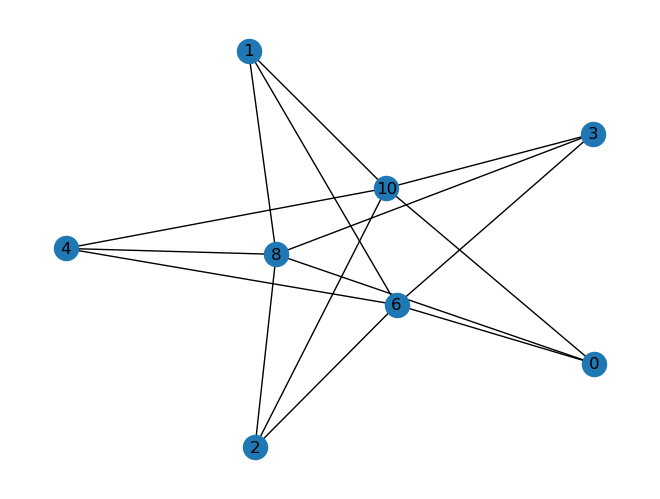

In [1]:
import networkx as nx

G = nx.Graph()
for i in range(0, 5):
    for j in range(2, 5):
        G.add_edge(i, 2*(j+1))

nx.draw(G, with_labels=True)

SyntaxError: unterminated string literal (detected at line 5) (3851271199.py, line 5)

In [10]:
import networkx as nx
from IPython.display import display, HTML
from html import escape
import json

G = nx.path_graph(["A", "B", "C", "D"])

pos = {
    "A": (100, 100),
    "B": (250, 150),
    "C": (400, 100),
    "D": (550, 200),
}

width = 650
height = 300

# Build edges
edges = ""

for u, v in G.edges:
    x1, y1 = pos[u]
    x2, y2 = pos[v]

    edges += f"""
    <line
        id="edge-{u}-{v}"
        x1="{x1}" y1="{y1}"
        x2="{x2}" y2="{y2}"
        stroke="black"
        stroke-width="2"
    />
    """

# Build nodes
nodes = ""

for node, (x, y) in pos.items():

    nodes += f"""
    <g
        class="node"
        data-node="{escape(str(node))}"
        transform="translate({x},{y})"
        style="cursor: grab;"
    >

        <circle
            cx="0"
            cy="0"
            r="20"
            fill="lightblue"
            stroke="black"
            stroke-width="2"
        />

        <text
            x="0"
            y="5"
            text-anchor="middle"
            font-size="14"
        >
            {escape(str(node))}
        </text>

    </g>
    """

# Initial position dictionary
initial_pos = json.dumps(
    {
        str(node): [float(x), float(y)]
        for node, (x, y) in pos.items()
    },
    indent=4
)

# =========================================================
# SINGLE F-STRING
# =========================================================

html = f"""
<div id="graph-editor">

<svg
    id="graph-svg"
    width="{width}"
    height="{height}"
    style="border:1px solid gray; user-select:none;"
>
    {edges}
    {nodes}
</svg>

<br><br>

<textarea
    id="position-output"
    style="
        width: 600px;
        height: 180px;
        font-family: monospace;
    "
>{escape(initial_pos)}</textarea>

</div>

<script>

(function() {{

    const svg =
        document.getElementById("graph-svg");

    const output =
        document.getElementById("position-output");


    let selectedNode = null;
    let offsetX = 0;
    let offsetY = 0;


    // =================================================
    // GET MOUSE POSITION
    // =================================================

    function getMousePosition(event) {{

        const rect =
            svg.getBoundingClientRect();

        return {{
            x: event.clientX - rect.left,
            y: event.clientY - rect.top
        }};
    }}


    // =================================================
    // UPDATE POSITION DICTIONARY
    // =================================================

    function updatePositionOutput() {{

        const positions = {{}};

        svg
            .querySelectorAll(".node")
            .forEach(node => {{

                const transform =
                    node
                        .getAttribute("transform")
                        .match(
                            /translate\\(([^,]+),([^\\)]+)\\)/
                        );

                const x =
                    parseFloat(transform[1]);

                const y =
                    parseFloat(transform[2]);

                positions[node.dataset.node] = [
                    Number(x.toFixed(3)),
                    Number(y.toFixed(3))
                ];

            }});

        output.value =
            JSON.stringify(
                positions,
                null,
                4
            );
    }}


    // =================================================
    // START DRAG
    // =================================================

    svg
        .querySelectorAll(".node")
        .forEach(node => {{

            node.addEventListener(
                "mousedown",
                function(event) {{

                    selectedNode = node;

                    const mouse =
                        getMousePosition(event);

                    const transform =
                        node
                            .getAttribute("transform")
                            .match(
                                /translate\\(([^,]+),([^\\)]+)\\)/
                            );

                    const x =
                        parseFloat(transform[1]);

                    const y =
                        parseFloat(transform[2]);

                    offsetX =
                        mouse.x - x;

                    offsetY =
                        mouse.y - y;

                    node.style.cursor =
                        "grabbing";

                    event.preventDefault();

                }}
            );

        }});


    // =================================================
    // DRAG
    // =================================================

    svg.addEventListener(
        "mousemove",
        function(event) {{

            if (!selectedNode)
                return;

            const mouse =
                getMousePosition(event);

            const x =
                mouse.x - offsetX;

            const y =
                mouse.y - offsetY;

            selectedNode.setAttribute(
                "transform",
                `translate(${{x}},${{y}})`
            );


            // -----------------------------------------
            // Update connected edges
            // -----------------------------------------

            const movedNode =
                selectedNode.dataset.node;

            svg
                .querySelectorAll("line")
                .forEach(edge => {{

                    const id =
                        edge.id;

                    if (!id.includes(movedNode))
                        return;

                    const parts =
                        id
                            .replace("edge-", "")
                            .split("-");

                    const u = parts[0];
                    const v = parts[1];

                    const otherNode =
                        u === movedNode
                            ? v
                            : u;

                    const other =
                        svg.querySelector(
                            `.node[data-node="${{otherNode}}"]`
                        );

                    const otherTransform =
                        other
                            .getAttribute("transform")
                            .match(
                                /translate\\(([^,]+),([^\\)]+)\\)/
                            );

                    const ox =
                        parseFloat(otherTransform[1]);

                    const oy =
                        parseFloat(otherTransform[2]);


                    if (u === movedNode) {{

                        edge.setAttribute(
                            "x1",
                            x
                        );

                        edge.setAttribute(
                            "y1",
                            y
                        );

                        edge.setAttribute(
                            "x2",
                            ox
                        );

                        edge.setAttribute(
                            "y2",
                            oy
                        );

                    }}
                    else {{

                        edge.setAttribute(
                            "x1",
                            ox
                        );

                        edge.setAttribute(
                            "y1",
                            oy
                        );

                        edge.setAttribute(
                            "x2",
                            x
                        );

                        edge.setAttribute(
                            "y2",
                            y
                        );

                    }}

                }});


            // -----------------------------------------
            // Update position dictionary
            // -----------------------------------------

            updatePositionOutput();

        }});


    // =================================================
    // END DRAG
    // =================================================

    svg.addEventListener(
        "mouseup",
        function() {{

            if (selectedNode)
                selectedNode.style.cursor = "grab";

            selectedNode = null;

            updatePositionOutput();

        }});


    // =================================================
    // INITIALIZE
    // =================================================

    updatePositionOutput();

}})();

</script>
"""

display(HTML(html))

In [4]:
import networkx as nx
from IPython.display import display, HTML
from html import escape
import json

G = nx.path_graph(["A", "B", "C", "D"])

pos = {
    "A": (100, 100),
    "B": (250, 150),
    "C": (400, 100),
    "D": (550, 200),
}

width = 650
height = 300

# ---------------------------------------------------------
# Build edges
# ---------------------------------------------------------

edges = ""

for u, v in G.edges:
    x1, y1 = pos[u]
    x2, y2 = pos[v]

    edges += f"""
    <line
        id="edge-{u}-{v}"
        x1="{x1}" y1="{y1}"
        x2="{x2}" y2="{y2}"
        stroke="black"
        stroke-width="2"
    />
    """


# ---------------------------------------------------------
# Build nodes
# ---------------------------------------------------------

nodes = ""

for node, (x, y) in pos.items():

    nodes += f"""
    <g class="node" data-node="{escape(str(node))}"
       transform="translate({x},{y})"
       style="cursor: grab;">

        <circle
            cx="0"
            cy="0"
            r="20"
            fill="lightblue"
            stroke="black"
            stroke-width="2"
        />

        <text
            x="0"
            y="5"
            text-anchor="middle"
            font-size="14"
        >
            {escape(str(node))}
        </text>

    </g>
    """


# ---------------------------------------------------------
# Initial dictionary
# ---------------------------------------------------------

initial_pos = json.dumps(
    {
        str(node): [x, y]
        for node, (x, y) in pos.items()
    },
    indent=4
)


# =========================================================
# ONE F-STRING
# =========================================================

html = f"""
<div id="graph-editor">

<svg
    id="graph-svg"
    width="{width}"
    height="{height}"
    style="border:1px solid gray; user-select:none;"
>
    {edges}
    {nodes}
</svg>

<br><br>

<textarea
    id="position-output"
    rows="10"
    cols="50"
    style="font-family: monospace;"
>{escape(initial_pos)}</textarea>

</div>

<script>

(function() {{

    const svg =
        document.getElementById("graph-svg");

    const output =
        document.getElementById("position-output");

    let selectedNode = null;
    let offsetX = 0;
    let offsetY = 0;


    function getMousePosition(event) {{

        const rect =
            svg.getBoundingClientRect();

        return {{
            x: event.clientX - rect.left,
            y: event.clientY - rect.top
        }};
    }}


    // ------------------------------------------------
    // POSITION OUTPUT
    // ------------------------------------------------

    function updatePositions() {{

        const result = {{}};

        svg.querySelectorAll(".node").forEach(node => {{

            const match =
                node
                    .getAttribute("transform")
                    .match(
                        /translate\\(([^,]+),([^\\)]+)\\)/
                    );

            result[node.dataset.node] = [
                Number(parseFloat(match[1]).toFixed(3)),
                Number(parseFloat(match[2]).toFixed(3))
            ];

        }});

        output.value =
            JSON.stringify(result, null, 4);
    }}


    // ------------------------------------------------
    // START DRAG
    // ------------------------------------------------

    svg.querySelectorAll(".node").forEach(node => {{

        node.addEventListener("mousedown", function(event) {{

            selectedNode = node;

            const mouse =
                getMousePosition(event);

            const transform =
                node
                    .getAttribute("transform")
                    .match(
                        /translate\\(([^,]+),([^\\)]+)\\)/
                    );

            const x =
                parseFloat(transform[1]);

            const y =
                parseFloat(transform[2]);

            offsetX =
                mouse.x - x;

            offsetY =
                mouse.y - y;

            node.style.cursor =
                "grabbing";

            event.preventDefault();
        }});

    }});


    // ------------------------------------------------
    // DRAG
    // ------------------------------------------------

    svg.addEventListener("mousemove", function(event) {{

        if (!selectedNode)
            return;

        const mouse =
            getMousePosition(event);

        const x =
            mouse.x - offsetX;

        const y =
            mouse.y - offsetY;

        selectedNode.setAttribute(
            "transform",
            `translate(${{x}},${{y}})`
        );


        // ------------------------------------------------
        // Update connected edges
        // ------------------------------------------------

        const movedNode =
            selectedNode.dataset.node;

        svg.querySelectorAll("line").forEach(edge => {{

            const id =
                edge.id;

            if (!id.includes(movedNode))
                return;

            const parts =
                id
                    .replace("edge-", "")
                    .split("-");

            const u = parts[0];
            const v = parts[1];

            const otherNode =
                u === movedNode ? v : u;

            const other =
                svg.querySelector(
                    `.node[data-node="${{otherNode}}"]`
                );

            const otherTransform =
                other
                    .getAttribute("transform")
                    .match(
                        /translate\\(([^,]+),([^\\)]+)\\)/
                    );

            const ox =
                parseFloat(otherTransform[1]);

            const oy =
                parseFloat(otherTransform[2]);


            if (u === movedNode) {{

                edge.setAttribute("x1", x);
                edge.setAttribute("y1", y);

                edge.setAttribute("x2", ox);
                edge.setAttribute("y2", oy);

            }}
            else {{

                edge.setAttribute("x1", ox);
                edge.setAttribute("y1", oy);

                edge.setAttribute("x2", x);
                edge.setAttribute("y2", y);

            }}

        }});


        // ------------------------------------------------
        // NEW: update displayed dictionary
        // ------------------------------------------------

        updatePositions();

    }});


    // ------------------------------------------------
    // END DRAG
    // ------------------------------------------------

    svg.addEventListener("mouseup", function() {{

        if (selectedNode)
            selectedNode.style.cursor = "grab";

        selectedNode = null;

        updatePositions();

    }});


    // Initial display

    updatePositions();

}})();

</script>
"""

display(HTML(html))

In [5]:
from IPython.display import display, HTML

html = """
<svg id="test" width="650" height="300"
     style="border:1px solid gray;">

    <circle
        id="node"
        cx="200"
        cy="150"
        r="25"
        fill="lightblue"
        stroke="black"
    />

</svg>

<script>

const svg = document.getElementById("test");
const node = document.getElementById("node");

let dragging = false;

node.addEventListener("mousedown", function(e) {
    dragging = true;
    e.preventDefault();
});

svg.addEventListener("mousemove", function(e) {

    if (!dragging)
        return;

    node.setAttribute("cx", e.offsetX);
    node.setAttribute("cy", e.offsetY);

});

svg.addEventListener("mouseup", function() {
    dragging = false;
});

</script>
"""

display(HTML(html))

In [14]:
import networkx as nx
from IPython.display import display, HTML
from html import escape
import json


G = nx.path_graph(["A", "B", "C", "D"])

pos = {
    "A": (100, 100),
    "B": (250, 150),
    "C": (400, 100),
    "D": (550, 200),
}

width = 650
height = 300


# =========================================================
# BUILD EDGES
# =========================================================

edges = ""

for u, v in G.edges:

    x1, y1 = pos[u]
    x2, y2 = pos[v]

    edges += f"""
    <line
        class="edge"
        data-u="{escape(str(u))}"
        data-v="{escape(str(v))}"
        x1="{x1}"
        y1="{y1}"
        x2="{x2}"
        y2="{y2}"
        stroke="black"
        stroke-width="2"
    />
    """


# =========================================================
# BUILD NODES
# =========================================================

nodes = ""

for node, (x, y) in pos.items():

    nodes += f"""
    <circle
        class="node"
        data-node="{escape(str(node))}"
        cx="{x}"
        cy="{y}"
        r="25"
        fill="lightblue"
        stroke="black"
        stroke-width="2"
    />

    <text
        class="label"
        data-node="{escape(str(node))}"
        x="{x}"
        y="{y + 5}"
        text-anchor="middle"
        font-size="14"
        pointer-events="none"
    >{escape(str(node))}</text>
    """


# =========================================================
# INITIAL POSITION DICTIONARY
# =========================================================

initial = json.dumps(
    {
        str(n): [float(x), float(y)]
        for n, (x, y) in pos.items()
    },
    indent=4
)


# =========================================================
# JAVASCRIPT
#
# This is deliberately NOT an f-string.
# Therefore normal JavaScript {} are safe.
# =========================================================

javascript = """
(function() {

    const svg = document.getElementById("graph");
    const output = document.getElementById("positions");

    const nodes = svg.querySelectorAll(".node");

    let dragging = false;
    let selected = null;


    // -----------------------------------------------------
    // Update displayed position dictionary
    // -----------------------------------------------------

    function updatePositions() {

        const positions = [];

        nodes.forEach(function(node) {

            const x = parseFloat(
                node.getAttribute("cx")
            );

            const y = parseFloat(
                node.getAttribute("cy")
            );

            positions.push(
                '"' +
                node.dataset.node +
                '": (' +
                Number(x.toFixed(3)) +
                ', ' +
                Number(y.toFixed(3)) +
                ')'
            );

        });

        output.value =
            "{\\n    " +
            positions.join(",\\n    ") +
            "\\n}";
    }


    // -----------------------------------------------------
    // Start dragging
    // -----------------------------------------------------

    nodes.forEach(function(node) {

        node.addEventListener(
            "mousedown",
            function(event) {

                dragging = true;
                selected = node;

                event.preventDefault();

            }
        );

    });


    // -----------------------------------------------------
    // Drag
    // -----------------------------------------------------

    svg.addEventListener(
        "mousemove",
        function(event) {

            if (!dragging || selected === null)
                return;

            const x = event.offsetX;
            const y = event.offsetY;


            // Move node

            selected.setAttribute("cx", x);
            selected.setAttribute("cy", y);


            // Move label

            const name = selected.dataset.node;

            const label = svg.querySelector(
                '.label[data-node="' + name + '"]'
            );

            label.setAttribute("x", x);
            label.setAttribute("y", y + 5);


            // Update edges

            svg.querySelectorAll(".edge").forEach(
                function(edge) {

                    const u = edge.dataset.u;
                    const v = edge.dataset.v;

                    const nodeU = svg.querySelector(
                        '.node[data-node="' + u + '"]'
                    );

                    const nodeV = svg.querySelector(
                        '.node[data-node="' + v + '"]'
                    );

                    edge.setAttribute(
                        "x1",
                        nodeU.getAttribute("cx")
                    );

                    edge.setAttribute(
                        "y1",
                        nodeU.getAttribute("cy")
                    );

                    edge.setAttribute(
                        "x2",
                        nodeV.getAttribute("cx")
                    );

                    edge.setAttribute(
                        "y2",
                        nodeV.getAttribute("cy")
                    );

                }
            );


            // Update dictionary

            updatePositions();

        }
    );


    // -----------------------------------------------------
    // End dragging
    // -----------------------------------------------------

    svg.addEventListener(
        "mouseup",
        function() {

            dragging = false;
            selected = null;

        }
    );


    svg.addEventListener(
        "mouseleave",
        function() {

            dragging = false;
            selected = null;

        }
    );


    // Initial dictionary

    updatePositions();

})();
"""


# =========================================================
# SINGLE HTML F-STRING
# =========================================================

html = f"""
<div id="graph-editor">

    <svg
        id="graph"
        width="{width}"
        height="{height}"
        style="
            border: 1px solid gray;
            user-select: none;
        "
    >

        {edges}
        {nodes}

    </svg>

    <br><br>

    <textarea
        id="positions"
        rows="10"
        cols="50"
        style="font-family: monospace;"
    >{escape(initial)}</textarea>

</div>

<script>
{javascript}
</script>
"""


display(HTML(html))